# Customer Intelligence Engine
## 05. Predictive Modelling

### Objective

This notebook develops a machine learning model to predict whether an existing customer will make another purchase within the next 30 days.

The analysis uses historical purchasing behaviour to identify patterns associated with future customer activity.

The goal is to support customer retention and targeted marketing decisions.

## 1. Load and inspect the dataset

Begin by loading the cleaned customer transaction dataset and then developing a predictive model, we need to understand the available variables, data types and transaction dates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned customer transactions
df = pd.read_csv("../data/processed/customers_clean.csv")
# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns.tolist())

# Preview the data
display(df.head())

Dataset shape: (779425, 9)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'TotalSales']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


## 2. Prepare transaction dates

Before developing the predictive model, we examine the transaction date range and verify that the data is suitable for time-based analysis.

This will help us define a historical observation period and a future prediction period.

In [2]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Check transaction date range
print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())

# Count unique customers
print("Unique customers:", df["Customer ID"].nunique())

# Check missing values
print("\nMissing values:")
print(df[["Customer ID", "InvoiceDate", "TotalSales"]].isna().sum())

Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00
Unique customers: 5878

Missing values:
Customer ID    0
InvoiceDate    0
TotalSales     0
dtype: int64


## 3. Define the observation and prediction periods

The objective is to predict whether an existing customer will make another purchase within the next 30 days.

We separate historical transactions from future transactions to prevent data leakage.

- Observation period: Transactions before 1 November 2011
- Prediction period: 1 November 2011 to 30 November 2011
- Target variable: 1 if a customer purchases during the prediction period, otherwise 0

Only customers with purchasing history before the prediction period are included.

In [3]:
# Define prediction dates
cutoff_date = pd.Timestamp("2011-11-01")
prediction_end = pd.Timestamp("2011-12-01")

# Historical transactions
historical_df = df[
    df["InvoiceDate"] < cutoff_date
].copy()

# Transactions during the prediction period
future_df = df[
    (df["InvoiceDate"] >= cutoff_date) &
    (df["InvoiceDate"] < prediction_end)
].copy()

# Keep positive purchases
historical_df = historical_df[
    historical_df["TotalSales"] > 0
]

future_df = future_df[
    future_df["TotalSales"] > 0
]

# Display results
print("Historical transactions:", len(historical_df))
print("Prediction-period transactions:", len(future_df))

print("\nHistorical customers:",
      historical_df["Customer ID"].nunique())

print("Prediction-period customers:",
      future_df["Customer ID"].nunique())

Historical transactions: 699230
Prediction-period transactions: 63168

Historical customers: 5659
Prediction-period customers: 1664


## 4. Create the target variable

The target variable indicates whether an existing customer makes another purchase during the 30-day prediction period.

- **1 — Repeat Purchase:** The customer purchased during November 2011.
- **0 — No Repeat Purchase:** The customer did not purchase during November 2011.

Only customers with historical purchasing activity are included.

This creates a binary classification problem that can be addressed using machine learning.

In [4]:
# Get customers who purchased during the historical period
historical_customers = historical_df["Customer ID"].unique()

# Get customers who purchased during the prediction period
future_customers = set(future_df["Customer ID"].unique())

# Create customer-level target dataset
customer_target = pd.DataFrame({
    "Customer ID": historical_customers
})

# Assign target variable
customer_target["RepeatPurchase"] = (
    customer_target["Customer ID"]
    .isin(future_customers)
    .astype(int)
)

# Display target distribution
print("Total historical customers:", len(customer_target))

print("\nTarget distribution:")
print(customer_target["RepeatPurchase"].value_counts())

print("\nTarget percentages:")
print(
    customer_target["RepeatPurchase"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(customer_target.head())

Total historical customers: 5659

Target distribution:
RepeatPurchase
0    4186
1    1473
Name: count, dtype: int64

Target percentages:
RepeatPurchase
0    73.97
1    26.03
Name: proportion, dtype: float64


,Customer ID,RepeatPurchase
0,13085,0
1,13078,1
2,15362,0
3,18102,1
4,12682,1


## 5. Feature Engineering

We create customer-level features from historical transaction data to describe purchasing behaviour.

The initial features are:

- **Recency:** Days since the customer's most recent purchase.
- **Frequency:** Number of unique purchase invoices.
- **Monetary:** Total historical customer spending.
- **Average Order Value:** Average spending per purchase invoice.

All features are calculated before the prediction period to avoid data leakage.

In [5]:
# Calculate customer-level purchasing features
customer_features = historical_df.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalSales", "sum")
).reset_index()

# Calculate recency in days
customer_features["Recency"] = (
    cutoff_date - customer_features["LastPurchase"]
).dt.days

# Calculate average order value
customer_features["AverageOrderValue"] = (
    customer_features["Monetary"] / customer_features["Frequency"]
)

# Select features for modelling
customer_features = customer_features[
    ["Customer ID", "Recency", "Frequency",
     "Monetary", "AverageOrderValue"]
]

# Display results
print("Customer features shape:", customer_features.shape)

display(customer_features.head())

# Check missing values
print("\nMissing values:")
print(customer_features.isna().sum())

Customer features shape: (5659, 5)


,Customer ID,Recency,Frequency,Monetary,AverageOrderValue
0,12346,286,12,77556.46,6463.038333
1,12347,0,7,4696.71,670.958571
2,12348,36,5,2019.40,403.880000
3,12349,368,3,2671.14,890.380000
4,12350,271,1,334.40,334.400000



Missing values:
Customer ID          0
Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
dtype: int64


## 6. Prepare the modelling dataset

We combine historical customer purchasing features with the repeat-purchase target variable.

Each row represents one customer, with four predictive features and a binary outcome indicating whether they purchased again during November 2011.

The dataset will serve as our final evaluation snapshot. Earlier historical snapshots will be used to train and validate the model without using future information.

In [6]:
# Combine customer features with the target variable
model_df = customer_features.merge(
    customer_target,
    on="Customer ID",
    how="inner",
    validate="one_to_one"
)

# Display dataset dimensions
print("Modelling dataset shape:", model_df.shape)

# Preview the dataset
display(model_df.head())

# Check missing values
print("\nMissing values:")
print(model_df.isna().sum())

# Check target distribution
print("\nTarget distribution:")
print(model_df["RepeatPurchase"].value_counts())

Modelling dataset shape: (5659, 6)


,Customer ID,Recency,Frequency,Monetary,AverageOrderValue,RepeatPurchase
0,12346,286,12,77556.46,6463.038333,0
1,12347,0,7,4696.71,670.958571,0
2,12348,36,5,2019.40,403.880000,0
3,12349,368,3,2671.14,890.380000,1
4,12350,271,1,334.40,334.400000,0



Missing values:
Customer ID          0
Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
RepeatPurchase       0
dtype: int64

Target distribution:
RepeatPurchase
0    4186
1    1473
Name: count, dtype: int64


## 7. Create historical training snapshots

To evaluate the model realistically, we use a time-based approach.

For each cutoff date, we calculate customer purchasing features using only transactions before that date. We then identify whether each customer purchases during the following month.

This approach allows us to train on earlier periods and evaluate performance on later periods without using future transactions as predictors.

In [7]:
def create_customer_snapshot(data, cutoff_date):
    cutoff_date = pd.Timestamp(cutoff_date)
    prediction_end = cutoff_date + pd.DateOffset(months=1)

    # Keep positive purchases
    purchases = data[data["TotalSales"] > 0].copy()

    # Separate historical and future transactions
    history = purchases[
        purchases["InvoiceDate"] < cutoff_date
    ]

    future = purchases[
        (purchases["InvoiceDate"] >= cutoff_date) &
        (purchases["InvoiceDate"] < prediction_end)
    ]

    # Calculate customer features
    features = history.groupby("Customer ID").agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("TotalSales", "sum")
    ).reset_index()

    features["Recency"] = (
        cutoff_date - features["LastPurchase"]
    ).dt.days

    features["AverageOrderValue"] = (
        features["Monetary"] / features["Frequency"]
    )

    # Create the repeat-purchase target
    future_customers = set(future["Customer ID"].unique())

    features["RepeatPurchase"] = (
        features["Customer ID"]
        .isin(future_customers)
        .astype(int)
    )

    return features[
        ["Customer ID", "Recency", "Frequency",
         "Monetary", "AverageOrderValue", "RepeatPurchase"]
    ]

In [8]:
# Test the function using the November 2011 snapshot
test_snapshot = create_customer_snapshot(df, "2011-11-01")

print("Snapshot shape:", test_snapshot.shape)

print("\nTarget distribution:")
print(test_snapshot["RepeatPurchase"].value_counts())

display(test_snapshot.head())

Snapshot shape: (5659, 6)

Target distribution:
RepeatPurchase
0    4186
1    1473
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,AverageOrderValue,RepeatPurchase
0,12346,286,12,77556.46,6463.038333,0
1,12347,0,7,4696.71,670.958571,0
2,12348,36,5,2019.40,403.880000,0
3,12349,368,3,2671.14,890.380000,1
4,12350,271,1,334.40,334.400000,0


## 8. Prepare training and validation datasets

We create historical customer snapshots to train and validate the repeat-purchase prediction model.

The training data uses snapshots from July, August and September 2011. October 2011 is reserved for validation, while November 2011 remains untouched for final testing.

The chronological approach helps evaluate how well the model generalises to future purchasing periods.

In [9]:
# Define training cutoff dates
training_dates = [
    "2011-07-01",
    "2011-08-01",
    "2011-09-01"
]

# Generate historical training snapshots
training_snapshots = []

for date in training_dates:
    snapshot = create_customer_snapshot(df, date)
    snapshot["SnapshotDate"] = date
    training_snapshots.append(snapshot)

# Combine training snapshots
train_df = pd.concat(training_snapshots, ignore_index=True)

# Create validation and test snapshots
validation_df = create_customer_snapshot(df, "2011-10-01")
test_df = create_customer_snapshot(df, "2011-11-01")

# Display dataset sizes
print("Training records:", len(train_df))
print("Validation records:", len(validation_df))
print("Test records:", len(test_df))

# Display repeat-purchase rates
print("\nRepeat-purchase rates:")
print("Training:", round(train_df["RepeatPurchase"].mean() * 100, 2), "%")
print("Validation:", round(validation_df["RepeatPurchase"].mean() * 100, 2), "%")
print("Test:", round(test_df["RepeatPurchase"].mean() * 100, 2), "%")

Training records: 15433
Validation records: 5438
Test records: 5659

Repeat-purchase rates:
Training: 17.84 %
Validation: 21.02 %
Test: 26.03 %


## 9. Train a Logistic Regression Model

Logistic Regression is used as the first classification model to predict whether a customer will purchase again during the following month.

The model uses four historical purchasing features:

- Recency
- Frequency
- Monetary
- Average Order Value

Feature scaling is applied because these variables have different numerical ranges.

The model is trained using historical snapshots from July to September 2011. October 2011 is used for validation, while November 2011 is reserved for final testing.

In [10]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Define predictive features
feature_cols = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue"
]

# Prepare training data
X_train = train_df[feature_cols]
y_train = train_df["RepeatPurchase"]

# Prepare validation data
X_val = validation_df[feature_cols]
y_val = validation_df["RepeatPurchase"]

# Create a modelling pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate validation predictions
val_predictions = logistic_model.predict(X_val)

# Generate predicted probabilities
val_probabilities = logistic_model.predict_proba(X_val)[:, 1]

print("Logistic Regression trained successfully!")

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Number of features:", len(feature_cols))

Logistic Regression trained successfully!
Training records: 15433
Validation records: 5438
Number of features: 4


## 10. Model Evaluation

We evaluate Logistic Regression using the October 2011 validation dataset.

The evaluation focuses on:

- Accuracy: Overall proportion of correct predictions.
- Precision: How often predicted repeat purchasers actually purchase.
- Recall: How many actual repeat purchasers the model identifies.
- F1-score: Balance between precision and recall.
- ROC-AUC: How effectively the model ranks repeat purchasers above non-purchasers.

Because repeat purchasers represent a minority of customers, accuracy alone may be misleading.

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Evaluate Logistic Regression on validation data
accuracy = accuracy_score(y_val, val_predictions)
precision = precision_score(y_val, val_predictions, zero_division=0)
recall = recall_score(y_val, val_predictions, zero_division=0)
f1 = f1_score(y_val, val_predictions, zero_division=0)
roc_auc = roc_auc_score(y_val, val_probabilities)

# Display evaluation metrics
print("Logistic Regression — Validation Results")
print("-" * 45)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_val, val_predictions, zero_division=0))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

Logistic Regression — Validation Results
---------------------------------------------
Accuracy:  0.813
Precision: 0.679
Recall:    0.211
F1-score:  0.322
ROC-AUC:   0.756

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4295
           1       0.68      0.21      0.32      1143

    accuracy                           0.81      5438
   macro avg       0.75      0.59      0.61      5438
weighted avg       0.79      0.81      0.77      5438


Confusion Matrix:
[[4181  114]
 [ 902  241]]


## 11. Baseline Model Comparison

To determine whether Logistic Regression provides value, we compare it against a simple majority-class baseline.

The baseline predicts that every customer will not make another purchase during the prediction period.

This comparison demonstrates why accuracy alone is insufficient when the target classes are imbalanced.

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

# Baseline: predict no repeat purchase for every customer
baseline_predictions = np.zeros(len(y_val), dtype=int)

# Compare baseline and Logistic Regression
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Baseline": [
        accuracy_score(y_val, baseline_predictions),
        precision_score(y_val, baseline_predictions, zero_division=0),
        recall_score(y_val, baseline_predictions, zero_division=0),
        f1_score(y_val, baseline_predictions, zero_division=0)
    ],
    "Logistic Regression": [
        accuracy_score(y_val, val_predictions),
        precision_score(y_val, val_predictions, zero_division=0),
        recall_score(y_val, val_predictions, zero_division=0),
        f1_score(y_val, val_predictions, zero_division=0)
    ]
})

display(comparison.round(3))

,Metric,Baseline,Logistic Regression
0,Accuracy,0.79,0.813
1,Precision,0.00,0.679
2,Recall,0.00,0.211
3,F1-score,0.00,0.322


## 12. Classification Threshold Optimisation

The default Logistic Regression threshold is 0.50.

However, this threshold may not provide the best balance between precision and recall.

We evaluate several classification thresholds using the October 2011 validation dataset.

The F1-score is used to select a threshold that balances identifying repeat purchasers with limiting false-positive predictions.

The November 2011 test dataset remains untouched during threshold selection.

In [14]:
# Evaluate different classification thresholds
thresholds = np.arange(0.10, 0.61, 0.05)

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    predictions = (val_probabilities >= threshold).astype(int)

    # Calculate evaluation metrics
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

# Identify the threshold with the highest F1-score
best_row = threshold_df.loc[threshold_df["F1-score"].idxmax()]
best_threshold = float(best_row["Threshold"])

print("\nBest threshold:", best_threshold)
print("Best validation F1-score:", round(best_row["F1-score"], 3))

,Threshold,Precision,Recall,F1-score
0,0.10,0.313,0.836,0.455
1,0.15,0.342,0.766,0.473
2,0.20,0.378,0.658,0.480
3,0.25,0.426,0.510,0.464
4,0.30,0.479,0.409,0.441
5,0.35,0.531,0.332,0.409
6,0.40,0.589,0.270,0.371
7,0.45,0.625,0.236,0.343
8,0.50,0.679,0.211,0.322
9,0.55,0.720,0.178,0.285



Best threshold: 0.2
Best validation F1-score: 0.48


## 13. Optimised Logistic Regression Evaluation

The classification threshold was reduced from 0.50 to 0.20 based on validation F1-score.

We now evaluate the resulting predictions to understand the improvement in recall and the additional false positives.

This evaluation uses the October 2011 validation dataset.

In [15]:
# Apply the selected classification threshold
optimised_predictions = (
    val_probabilities >= best_threshold
).astype(int)

# Calculate optimised evaluation metrics
print("Optimised Logistic Regression")
print("-" * 40)

print("Threshold:", best_threshold)

print(
    "Accuracy:",
    round(accuracy_score(y_val, optimised_predictions), 3)
)

print(
    "Precision:",
    round(precision_score(y_val, optimised_predictions), 3)
)

print(
    "Recall:",
    round(recall_score(y_val, optimised_predictions), 3)
)

print(
    "F1-score:",
    round(f1_score(y_val, optimised_predictions), 3)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, optimised_predictions))

Optimised Logistic Regression
----------------------------------------
Threshold: 0.2
Accuracy: 0.7
Precision: 0.378
Recall: 0.658
F1-score: 0.48

Confusion Matrix:
[[3056 1239]
 [ 391  752]]


## 14. Random Forest Classification

Random Forest is introduced as a second machine learning algorithm.

Unlike Logistic Regression, Random Forest can capture nonlinear relationships and interactions between customer purchasing features.

The model uses the same four predictors and the same chronological training and validation datasets to ensure a fair comparison.

We first evaluate Random Forest using its default classification threshold of 0.50.

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Train using the same training dataset
rf_model.fit(X_train, y_train)

# Generate validation predictions
rf_predictions = rf_model.predict(X_val)

# Generate predicted probabilities
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Evaluate Random Forest
print("Random Forest — Validation Results")
print("-" * 40)

print(
    "Accuracy:",
    round(accuracy_score(y_val, rf_predictions), 3)
)

print(
    "Precision:",
    round(precision_score(y_val, rf_predictions, zero_division=0), 3)
)

print(
    "Recall:",
    round(recall_score(y_val, rf_predictions, zero_division=0), 3)
)

print(
    "F1-score:",
    round(f1_score(y_val, rf_predictions, zero_division=0), 3)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, rf_probabilities), 3)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_predictions))

Random Forest — Validation Results
----------------------------------------
Accuracy: 0.813
Precision: 0.653
Recall: 0.235
F1-score: 0.346
ROC-AUC: 0.762

Confusion Matrix:
[[4152  143]
 [ 874  269]]


## 15. Model Performance Comparison

We compare Logistic Regression and Random Forest using the October 2011 validation dataset.

Both models are initially evaluated at the default classification threshold of 0.50 to provide a consistent comparison.

The evaluation focuses on accuracy, precision, recall, F1-score and ROC-AUC.

In [18]:
# Create model comparison table
model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        0.813, 0.679, 0.211, 0.322, 0.756
    ],
    "Random Forest": [
        0.813, 0.653, 0.235, 0.346, 0.762
    ]
})

display(model_comparison)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.813,0.813
1,Precision,0.679,0.653
2,Recall,0.211,0.235
3,F1-score,0.322,0.346
4,ROC-AUC,0.756,0.762


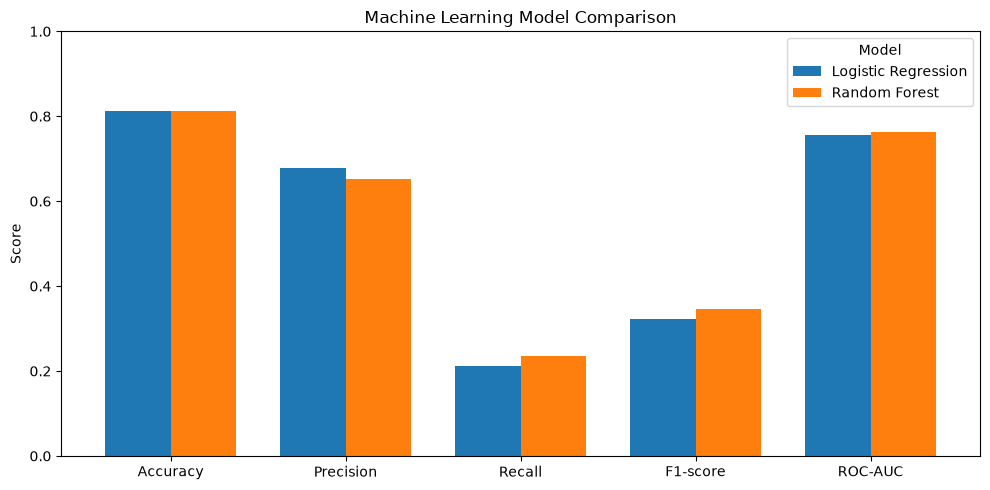

In [19]:
# Visualise model performance
chart_data = model_comparison.set_index("Metric")

ax = chart_data.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Machine Learning Model Comparison")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. Random Forest Threshold Optimisation

We evaluate different classification thresholds for Random Forest using the October 2011 validation dataset.

The threshold with the highest F1-score will be selected and compared with the optimised Logistic Regression model.

The November 2011 test dataset remains reserved for final evaluation.

In [20]:
# Evaluate Random Forest at different thresholds
rf_threshold_results = []

for threshold in np.arange(0.10, 0.61, 0.05):

    predictions = (rf_probabilities >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

# Create a results table
rf_threshold_df = pd.DataFrame(rf_threshold_results)

display(rf_threshold_df.round(3))

# Find the best threshold
rf_best_row = rf_threshold_df.loc[
    rf_threshold_df["F1-score"].idxmax()
]

rf_best_threshold = float(rf_best_row["Threshold"])

print("\nBest Random Forest threshold:", rf_best_threshold)
print(
    "Best validation F1-score:",
    round(rf_best_row["F1-score"], 3)
)

,Threshold,Precision,Recall,F1-score
0,0.10,0.327,0.809,0.466
1,0.15,0.357,0.737,0.481
2,0.20,0.386,0.650,0.485
3,0.25,0.427,0.525,0.471
4,0.30,0.489,0.437,0.462
5,0.35,0.525,0.370,0.434
6,0.40,0.575,0.304,0.398
7,0.45,0.612,0.254,0.359
8,0.50,0.653,0.235,0.346
9,0.55,0.676,0.217,0.328



Best Random Forest threshold: 0.2
Best validation F1-score: 0.485


## 17. Optimised Model Comparison

Both Logistic Regression and Random Forest were evaluated using different classification thresholds.

A threshold of 0.20 produced the highest validation F1-score for both models among the thresholds tested.

We compare the optimised models using precision, recall, F1-score and ROC-AUC before selecting a final model.

In [21]:
# Apply the optimised thresholds
lr_optimised = (val_probabilities >= best_threshold).astype(int)
rf_optimised = (rf_probabilities >= rf_best_threshold).astype(int)

# Compare both models
optimised_comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [
        precision_score(y_val, lr_optimised),
        recall_score(y_val, lr_optimised),
        f1_score(y_val, lr_optimised),
        roc_auc_score(y_val, val_probabilities)
    ],
    "Random Forest": [
        precision_score(y_val, rf_optimised),
        recall_score(y_val, rf_optimised),
        f1_score(y_val, rf_optimised),
        roc_auc_score(y_val, rf_probabilities)
    ]
})

display(optimised_comparison.round(3))

,Metric,Logistic Regression,Random Forest
0,Precision,0.378,0.386
1,Recall,0.658,0.650
2,F1-score,0.480,0.485
3,ROC-AUC,0.756,0.762


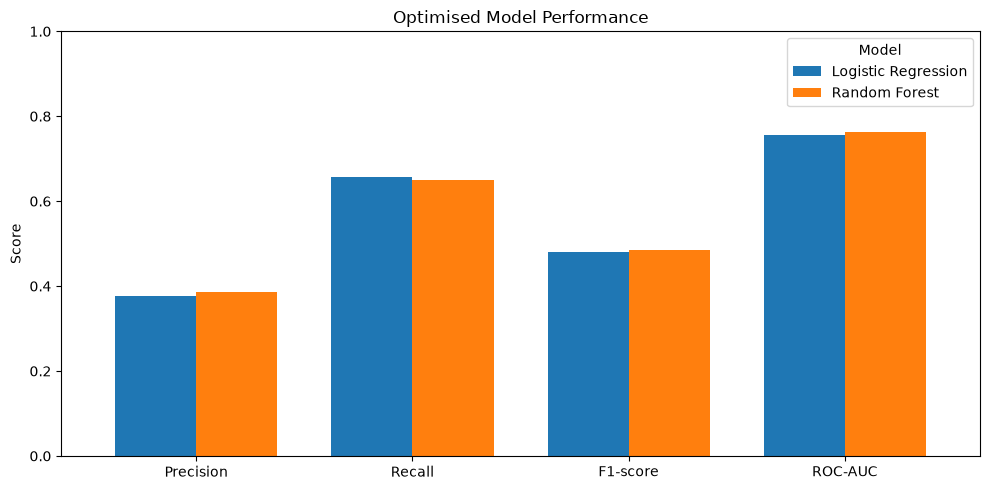

In [22]:
# Create optimised model comparison chart
chart_data = optimised_comparison.set_index("Metric")

ax = chart_data.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Optimised Model Performance")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 18. Final Model Selection

Logistic Regression was selected as the final model because it provides competitive predictive performance while remaining relatively simple and interpretable.

Although Random Forest achieved a slightly higher validation F1-score (0.485 compared with 0.480), the difference was small.

Logistic Regression also achieved slightly higher recall, identifying a greater proportion of actual repeat purchasers.

The selected classification threshold is 0.20, based on the October 2011 validation results.

The final model will now be evaluated on the November 2011 test dataset, which has not been used for model selection or threshold optimisation.

In [23]:
# Prepare the final test dataset
X_test = test_df[feature_cols]
y_test = test_df["RepeatPurchase"]

# Use our selected Logistic Regression model
final_model = logistic_model
final_threshold = best_threshold

# Generate predicted probabilities
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# Calculate final test metrics
print("Final Logistic Regression — Test Results")
print("-" * 45)

print("Threshold:", final_threshold)

print(
    "Accuracy:",
    round(accuracy_score(y_test, test_predictions), 3)
)

print(
    "Precision:",
    round(precision_score(y_test, test_predictions), 3)
)

print(
    "Recall:",
    round(recall_score(y_test, test_predictions), 3)
)

print(
    "F1-score:",
    round(f1_score(y_test, test_predictions), 3)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, test_probabilities), 3)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

Final Logistic Regression — Test Results
---------------------------------------------
Threshold: 0.2
Accuracy: 0.7
Precision: 0.451
Recall: 0.701
F1-score: 0.549
ROC-AUC: 0.773

Confusion Matrix:
[[2931 1255]
 [ 440 1033]]


## 19. Final Model Performance

The selected Logistic Regression model was evaluated on the November 2011 test dataset using a classification threshold of 0.20.

The model achieved an F1-score of 0.549 and ROC-AUC of 0.773.

It identified approximately 70% of actual repeat purchasers, although its precision of 45.1% indicates that some predicted purchasers did not make another purchase.

These results demonstrate the potential of historical purchasing behaviour for repeat-purchase prediction, while highlighting the trade-off between identifying more customers and limiting false positives.

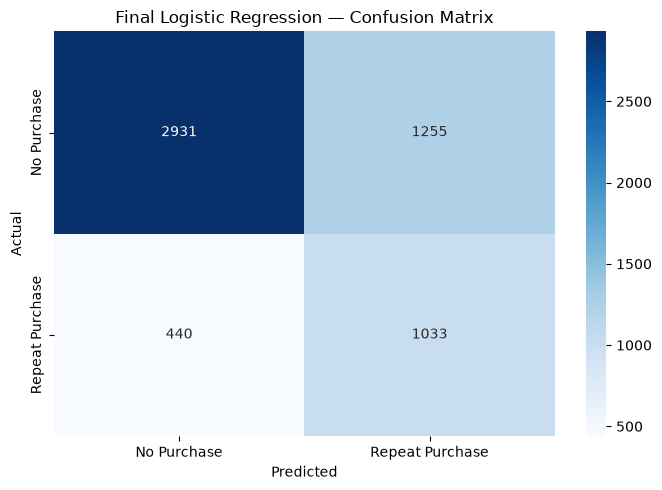

In [24]:
# Visualise the final confusion matrix
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Repeat Purchase"],
    yticklabels=["No Purchase", "Repeat Purchase"]
)

plt.title("Final Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

## 20. Feature Interpretation

To better understand the Logistic Regression model, we examine its feature coefficients.

Because the input features were standardised during training, their coefficients can be compared on a common scale.

Positive coefficients indicate an association with higher predicted repeat-purchase likelihood, while negative coefficients indicate an association with lower predicted likelihood.

These relationships are predictive associations rather than evidence of causation.

In [25]:
# Extract coefficients from Logistic Regression
coefficients = final_model.named_steps[
    "classifier"
].coef_[0]

# Create a feature interpretation table
feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": coefficients
})

# Sort by absolute coefficient size
feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(feature_importance.round(3))

,Feature,Coefficient,Absolute Coefficient
1,Frequency,1.029,1.029
0,Recency,-0.946,0.946
2,Monetary,-0.090,0.090
3,AverageOrderValue,0.070,0.070


## 21. Feature Coefficient Visualisation

The standardised Logistic Regression coefficients show that Frequency and Recency have the strongest associations with predicted repeat purchases.

Frequency has a positive coefficient, while Recency has a negative coefficient.

Monetary and Average Order Value have relatively small coefficients after accounting for the other features.

These results provide useful predictive insights, although they do not establish causal relationships.

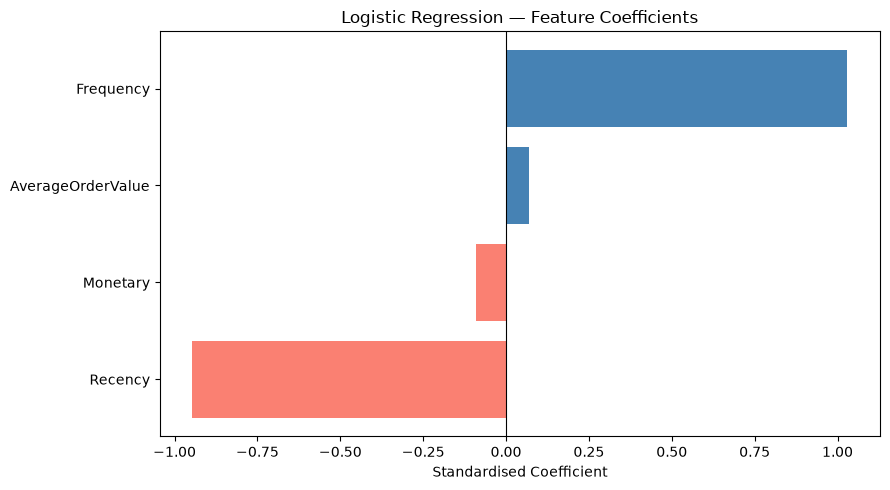

In [26]:
# Sort features by coefficient
plot_data = feature_importance.sort_values("Coefficient")

# Create horizontal bar chart
plt.figure(figsize=(9, 5))

colors = [
    "steelblue" if value > 0 else "salmon"
    for value in plot_data["Coefficient"]
]

plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"],
    color=colors
)

# Add reference line at zero
plt.axvline(0, color="black", linewidth=0.8)

plt.title("Logistic Regression — Feature Coefficients")
plt.xlabel("Standardised Coefficient")
plt.ylabel("")

plt.tight_layout()
plt.show()

## 22. Customer-Level Purchase Predictions

The final Logistic Regression model is used to generate repeat-purchase predictions for customers in the November 2011 test dataset.

Each customer receives a predicted probability of purchasing again, along with a classification based on the selected threshold of 0.20.

These predictions can support customer intelligence reporting and help businesses identify customers with different purchasing patterns.

The predictions are retrospective test results, not forecasts for the present day.

In [27]:
# Create customer-level prediction table
customer_predictions = test_df[
    ["Customer ID", "Recency", "Frequency",
     "Monetary", "AverageOrderValue"]
].copy()

# Add model predictions
customer_predictions["PurchaseProbability"] = test_probabilities

customer_predictions["PredictedRepeatPurchase"] = test_predictions

# Add actual outcomes for evaluation
customer_predictions["ActualRepeatPurchase"] = y_test.to_numpy()

# Sort customers by predicted probability
customer_predictions = customer_predictions.sort_values(
    "PurchaseProbability",
    ascending=False
)

# Display top 10 customers
display(customer_predictions.head(10).round(3))

print("Total customers:", len(customer_predictions))

,Customer ID,Recency,Frequency,Monetary,AverageOrderValue,PurchaseProbability,PredictedRepeatPurchase,ActualRepeatPurchase
2444,14911,0,355,261746.16,737.313,1.0,1,1
380,12748,5,282,42086.95,149.245,1.0,1,1
2827,15311,3,195,106011.07,543.647,1.0,1,1
5236,17841,0,191,59023.77,309.025,1.0,1,1
707,13089,1,192,104273.20,543.090,1.0,1,1
2155,14606,3,181,28493.22,157.421,1.0,1,1
5245,17850,333,155,51208.87,330.380,1.0,1,0
1719,14156,10,151,306684.94,2031.026,1.0,1,1
1275,13694,3,138,187670.31,1359.930,1.0,1,1
2584,15061,10,123,116704.24,948.815,1.0,1,1


Total customers: 5659


## 23. Export Customer Intelligence Predictions

The final model predictions are prepared for business intelligence reporting.

The dataset includes customer purchasing features, predicted repeat-purchase probabilities, and predicted classifications.

Predictions are based on customer activity before 1 November 2011 and represent estimated repeat-purchase likelihood during November 2011.

Actual November outcomes are excluded from the reporting export to avoid mixing future information with predictions.

In [28]:
# Prepare customer intelligence dataset
customer_intelligence = customer_predictions[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "AverageOrderValue",
        "PurchaseProbability",
        "PredictedRepeatPurchase"
    ]
].copy()

# Add prediction period
customer_intelligence["PredictionMonth"] = "2011-11"

# Export to processed data folder
output_path = "../data/processed/customer_predictions.csv"

customer_intelligence.to_csv(output_path, index=False)

print("Customer intelligence dataset saved successfully!")
print("Total customers:", len(customer_intelligence))
print("Total columns:", len(customer_intelligence.columns))

display(customer_intelligence.head().round(3))

Customer intelligence dataset saved successfully!
Total customers: 5659
Total columns: 8


,Customer ID,Recency,Frequency,Monetary,AverageOrderValue,PurchaseProbability,PredictedRepeatPurchase,PredictionMonth
2444,14911,0,355,261746.16,737.313,1.0,1,2011-11
380,12748,5,282,42086.95,149.245,1.0,1,2011-11
2827,15311,3,195,106011.07,543.647,1.0,1,2011-11
5236,17841,0,191,59023.77,309.025,1.0,1,2011-11
707,13089,1,192,104273.20,543.090,1.0,1,2011-11


## 24. Customer Purchase Likelihood Analysis

Customers are grouped into four categories based on their predicted repeat-purchase probabilities.

This analysis helps summarise the distribution of customer predictions and supports business intelligence reporting.

The categories are descriptive probability bands, not independently validated customer segments.

In [29]:
# Group customers by predicted purchase probability
customer_intelligence["LikelihoodGroup"] = pd.cut(
    customer_intelligence["PurchaseProbability"],
    bins=[-0.001, 0.20, 0.40, 0.60, 1.0],
    labels=["Low", "Moderate", "High", "Very High"]
)

# Summarise customers by likelihood group
likelihood_summary = (
    customer_intelligence
    .groupby("LikelihoodGroup", observed=True)
    .agg(
        Customers=("Customer ID", "count"),
        AverageProbability=("PurchaseProbability", "mean")
    )
    .reset_index()
)

# Calculate percentage of customers
likelihood_summary["Percentage"] = (
    likelihood_summary["Customers"]
    / len(customer_intelligence) * 100
)

display(likelihood_summary.round(2))

,LikelihoodGroup,Customers,AverageProbability,Percentage
0,Low,3371,0.07,59.57
1,Moderate,1717,0.27,30.34
2,High,317,0.48,5.60
3,Very High,254,0.79,4.49


## 25. Export Final Customer Intelligence Dataset

The customer-level prediction dataset is updated to include purchase-likelihood categories.

This final dataset combines historical purchasing features, model predictions and descriptive likelihood groups.

It will be used for customer intelligence reporting and future Power BI visualisations.

In [30]:
# Export updated customer intelligence dataset
customer_intelligence.to_csv(
    "../data/processed/customer_predictions.csv",
    index=False
)

print("Updated customer intelligence dataset saved!")
print("Total customers:", len(customer_intelligence))
print("Total columns:", len(customer_intelligence.columns))

# Check the distribution of likelihood groups
print("\nLikelihood group distribution:")
print(customer_intelligence["LikelihoodGroup"].value_counts())

# Display sample
display(customer_intelligence.head().round(3))

Updated customer intelligence dataset saved!
Total customers: 5659
Total columns: 9

Likelihood group distribution:
LikelihoodGroup
Low          3371
Moderate     1717
High          317
Very High     254
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,AverageOrderValue,PurchaseProbability,PredictedRepeatPurchase,PredictionMonth,LikelihoodGroup
2444,14911,0,355,261746.16,737.313,1.0,1,2011-11,Very High
380,12748,5,282,42086.95,149.245,1.0,1,2011-11,Very High
2827,15311,3,195,106011.07,543.647,1.0,1,2011-11,Very High
5236,17841,0,191,59023.77,309.025,1.0,1,2011-11,Very High
707,13089,1,192,104273.20,543.090,1.0,1,2011-11,Very High



## 26. Conclusion and Business Recommendations

This analysis developed a machine learning model to predict whether existing retail customers would purchase again during the following month.

Logistic Regression and Random Forest were trained using historical purchasing behaviour and evaluated using chronological validation data. Logistic Regression was selected because it provided competitive performance while remaining easier to interpret.

On the November 2011 test dataset, the selected Logistic Regression model achieved:

- **Accuracy:** 70.0%
- **Precision:** 45.1%
- **Recall:** 70.1%
- **F1-score:** 0.549
- **ROC-AUC:** 0.773

The model correctly identified 1,033 of the 1,473 customers who purchased again during November.

### Key Findings

Purchase frequency and recency showed the strongest associations with predicted repeat purchases. Customers who purchased more frequently and more recently generally had higher predicted purchase likelihood.

The model also generated customer-level predictions for 5,659 customers, providing a foundation for customer intelligence reporting.

### Business Recommendations

1. **Monitor customer engagement:** Use recency and frequency metrics to identify changes in customer purchasing behaviour.
2. **Prioritise customer analysis:** Use predicted purchase likelihood alongside customer segments to understand different customer groups.
3. **Support marketing planning:** Use model predictions to inform customer targeting decisions, while testing whether campaigns actually improve purchasing outcomes.
4. **Develop BI reporting:** Integrate customer segmentation and predictive analytics into a Power BI dashboard.

### Limitations

The model was evaluated on a single held-out month, so its performance may differ across other periods. Predicted probabilities have not been formally assessed for calibration, and the model does not measure the causal impact of marketing activities.

Future improvements could include additional validation periods, more behavioural features and evaluation of campaign effectiveness.
